# 4층 · 생성형 AI 실습

프롬프트를 AI에게 보내 받은 파이썬 코드입니다. 위에서부터 셀을 차례로 실행해 보세요.
데이터는 GitHub 저장소에서 바로 불러옵니다.

저장된 결과는 Python 3.13.18 · pandas 3.0.5 · scikit-learn 1.9.1 · NumPy 2.5.3 · matplotlib 3.11.2 로 실행한 것입니다. Colab에서는 라이브러리 버전에 따라 소수점이 조금 다를 수 있습니다.

## 실습 1 · 도미와 빙어를 점으로 찍어 보기

**프롬프트**

> 도미 35마리와 빙어 14마리의 길이·무게 데이터(fish_bream_smelt.csv)가 있어요.
> 길이를 가로축, 무게를 세로축으로 산점도를 그려 주세요.
> 종류마다 색을 다르게 하고, 그래프 글자는 영어로 해 주세요.

species
bream    35
smelt    14
Name: count, dtype: int64


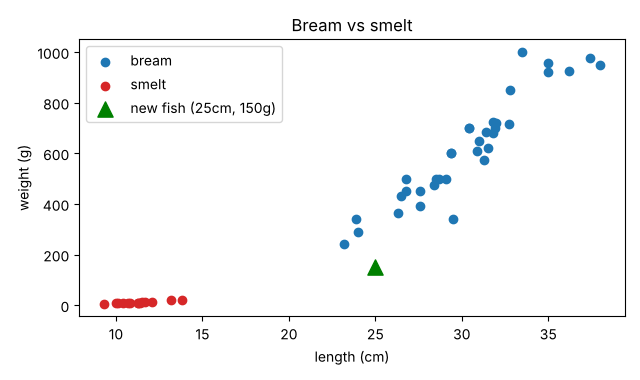

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

fish = pd.read_csv("https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/fish_bream_smelt.csv")
print(fish["species"].value_counts())

for sp, color in [("bream", "tab:blue"), ("smelt", "tab:red")]:
    part = fish[fish["species"] == sp]
    plt.scatter(part["length"], part["weight"], label=sp, color=color)
plt.scatter(25, 150, marker="^", s=120, color="green", label="new fish (25cm, 150g)")
plt.xlabel("length (cm)"); plt.ylabel("weight (g)"); plt.legend(); plt.title("Bream vs smelt")
plt.show()

**박사의 한 줄 판단** — 초록 세모(25cm, 150g)는 길이로 보면 도미 무리 가까이 있습니다. 하지만 세로축 숫자(무게)가 훨씬 커서 컴퓨터는 다르게 볼 수 있어요. 다음 카드에서 확인합니다.

## 실습 2 · 수상한 생선 — 표준화 전과 후

**프롬프트**

> k-NN(k=5)으로 길이 25cm·무게 150g인 생선이 도미인지 빙어인지 판정해 주세요.
> 원래 단위 그대로 한 번, 표준화(평균 0·표준편차 1)한 뒤 한 번.
> 두 경우 가장 가까운 이웃 5마리의 종류도 보여 주세요.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

fish = pd.read_csv("https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/fish_bream_smelt.csv")
X = fish[["length", "weight"]].to_numpy()
y = fish["species"].to_numpy()
new = np.array([[25, 150]])

# ① 원래 단위
kn = KNeighborsClassifier(n_neighbors=5).fit(X, y)
idx = kn.kneighbors(new, return_distance=False)[0]
print("원래 단위 → 판정:", kn.predict(new)[0], "/ 이웃:", list(y[idx]))

# ② 표준화: (값 − 평균) ÷ 표준편차
mean, std = X.mean(axis=0), X.std(axis=0)
Xs, new_s = (X - mean) / std, (new - mean) / std
kn_s = KNeighborsClassifier(n_neighbors=5).fit(Xs, y)
idx = kn_s.kneighbors(new_s, return_distance=False)[0]
print("표준화 후 → 판정:", kn_s.predict(new_s)[0], "/ 이웃:", list(y[idx]))

원래 단위 → 판정: smelt / 이웃: ['bream', 'smelt', 'smelt', 'smelt', 'smelt']
표준화 후 → 판정: bream / 이웃: ['bream', 'bream', 'bream', 'bream', 'bream']


**박사의 한 줄 판단** — 원래 단위에서는 이웃 5마리 중 4마리가 빙어라 ‘빙어’, 표준화하니 5마리 모두 도미라 ‘도미’입니다. 단위가 다른 특성은 같은 자로 바꿔야 한다는 것을 결과가 그대로 보여 줍니다.